# Lanzar monedas

In [ ]:
import random
import matplotlib.pyplot as plt
from collections import Counter
import numpy as np

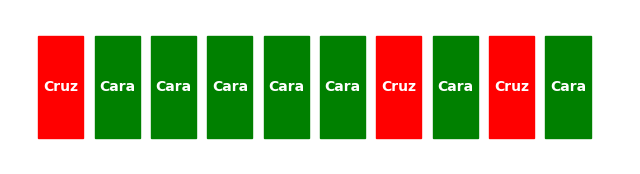

In [ ]:
# 1. Simulación con NumPy (1 = Cara, 0 = Cruz)
lanzamientos = np.random.randint(0, 2, size=10)
exitos = np.sum(lanzamientos)  # Cuenta cuántos '1' hay

# 2. Configuración del gráfico
fig, ax = plt.subplots(figsize=(8, 2))

# Dibujar cada lanzamiento como un cuadrado
for i, resultado in enumerate(lanzamientos):
    color = 'green' if resultado == 1 else 'red'
    # plt.Rectangle((x, y), ancho, alto)
    cuadrado = plt.Rectangle((i, 0), 0.8, 0.8, color=color)
    ax.add_patch(cuadrado)

    # Texto opcional dentro del cuadrado para identificarlo
    ax.text(i + 0.4, 0.4, 'Cara' if resultado == 1 else 'Cruz',
            color='white', ha='center', va='center', fontweight='bold')

# Ajustar límites y quitar ejes para que solo se vean los cuadrados
ax.set_xlim(-0.5, 10.5)
ax.set_ylim(-0.2, 1.0)
ax.axis('off')

# Título con el número de éxitos
#plt.title(f"Un experimento (10 lanzamientos)\nÉxitos totales (Caras): {exitos}", fontsize=12, pad=10)
plt.savefig('c1_experimento_10_lanzamientos.png')
plt.show()

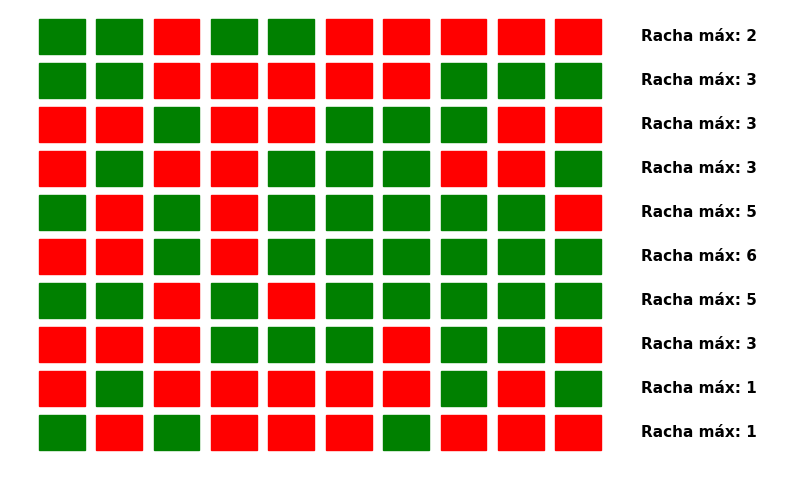

In [ ]:
# Función auxiliar para calcular la racha máxima de Caras (1s) en una fila
def obtener_racha_maxima(fila):
    racha_maxima = 0
    racha_actual = 0
    for resultado in fila:
        if resultado == 1:
            racha_actual += 1
            if racha_actual > racha_maxima:
                racha_maxima = racha_actual
        else:
            racha_actual = 0  # Se rompe la racha, volvemos a empezar
    return racha_maxima

# 1. Simulación de 10 experimentos de 10 lanzamientos (Matriz 10x10)
matriz_experimentos = np.random.randint(0, 2, size=(10, 10))

# 2. Configuración del gráfico
fig, ax = plt.subplots(figsize=(10, 6))

# Dibujar las filas de experimentos
for fila in range(10):
    # Calculamos la racha de la fila actual usando nuestra función
    racha_max = obtener_racha_maxima(matriz_experimentos[fila])

    for columna in range(10):
        resultado = matriz_experimentos[fila, columna]
        color = 'green' if resultado == 1 else 'red'

        # Invertimos el orden de la fila (9 - fila) para que el experimento 1 quede arriba
        cuadrado = plt.Rectangle((columna, 9 - fila), 0.8, 0.8, color=color)
        ax.add_patch(cuadrado)

    # Colocar el label de racha máxima al final de cada fila
    ax.text(10.5, 9 - fila + 0.4, f"Racha máx: {racha_max}",
            va='center', ha='left', fontsize=11, fontweight='bold', color='black')

# Ajustar los límites del lienzo para que quepa el texto de la derecha
ax.set_xlim(-0.5, 13)
ax.set_ylim(-0.5, 10)
ax.axis('off')

#plt.title("10 Experimentos (Visualización de racha máxima de Caras)", fontsize=14, pad=15)
plt.savefig('c1_experimentos_10_iteraciones.png')
plt.show()

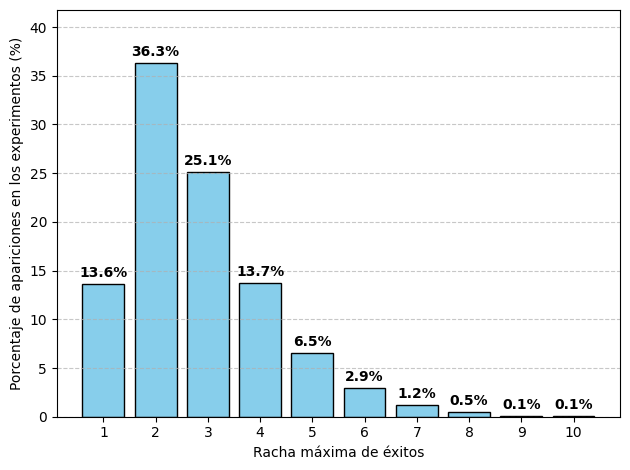

In [ ]:


# Configuración de la simulación
REPETICIONES = 1000
LANZAMIENTOS_PER_INTENTO = 10

maximas_rachas_totales = []

for _ in range(REPETICIONES):
    # Simulamos 10 lanzamientos: 1 es "Éxito" y 0 es "Fracaso"
    lanzamientos = [random.randint(0, 1) for _ in range(LANZAMIENTOS_PER_INTENTO)]

    racha_actual = 0
    max_racha_intento = 0

    # Analizamos la racha de éxitos en este intento
    for resultado in lanzamientos:
        if resultado == 1:
            racha_actual += 1
            if racha_actual > max_racha_intento:
                max_racha_intento = racha_actual
        else:
            racha_actual = 0

    maximas_rachas_totales.append(max_racha_intento)

# --- Filtrado y Preparación de los Datos ---

# Conservamos el filtro desde 1 como decidiste en el paso anterior
rachas_filtradas = [r for r in maximas_rachas_totales if r >= 1]

# Contamos la frecuencia de cada racha filtrada
frecuencias = Counter(rachas_filtradas)

# Ordenamos los valores de menor a mayor racha para el eje X
x_values = sorted(frecuencias.keys())

# Volvemos a calcular el porcentaje multiplicando por 100
y_values = [(frecuencias[x] / REPETICIONES) * 100 for x in x_values]

# --- Creación del Barplot ---

# Dibujamos las barras y las guardamos en una variable 'barras'
barras = plt.bar(x_values, y_values, color='skyblue', edgecolor='black')

# AGREGAR PORCENTAJES ARRIBA DE LAS BARRAS
# El parámetro fmt='%.1f%%' muestra el porcentaje con un decimal
plt.bar_label(barras, fmt='%.1f%%', padding=3, fontsize=10, fontweight='bold')

# Configuramos etiquetas y título actualizados a porcentajes
plt.xlabel('Racha máxima de éxitos')
plt.ylabel('Porcentaje de apariciones en los experimentos (%)')
#plt.title('Distribución de rachas máximas de éxitos', fontsize=14, pad=15)

# Nos aseguramos de que solo se muestren los números enteros correspondientes en el eje X
plt.xticks(x_values)

# Añadimos una cuadrícula ligera de fondo para facilitar la lectura
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Ampliamos un poco el límite superior del eje Y para evitar que se corten los textos
plt.ylim(0, max(y_values) * 1.15)

# Ajustamos los márgenes de forma automática para evitar cortes en el texto
plt.tight_layout()

# Guardamos el gráfico como imagen en el almacenamiento local
plt.savefig('c1_barras_rachas_caras.png')
plt.show()

Iniciando simulación...
------------------------------------------------------------
Moneda con 50% de probabilidad de Cara -> Logró 10 caras: 1 veces (0.1%)
Moneda con 55% de probabilidad de Cara -> Logró 10 caras: 4 veces (0.4%)
Moneda con 60% de probabilidad de Cara -> Logró 10 caras: 5 veces (0.5%)
Moneda con 65% de probabilidad de Cara -> Logró 10 caras: 8 veces (0.8%)
Moneda con 70% de probabilidad de Cara -> Logró 10 caras: 40 veces (4.0%)
Moneda con 75% de probabilidad de Cara -> Logró 10 caras: 61 veces (6.1%)
Moneda con 80% de probabilidad de Cara -> Logró 10 caras: 108 veces (10.8%)
Moneda con 85% de probabilidad de Cara -> Logró 10 caras: 177 veces (17.7%)
Moneda con 90% de probabilidad de Cara -> Logró 10 caras: 357 veces (35.7%)
------------------------------------------------------------


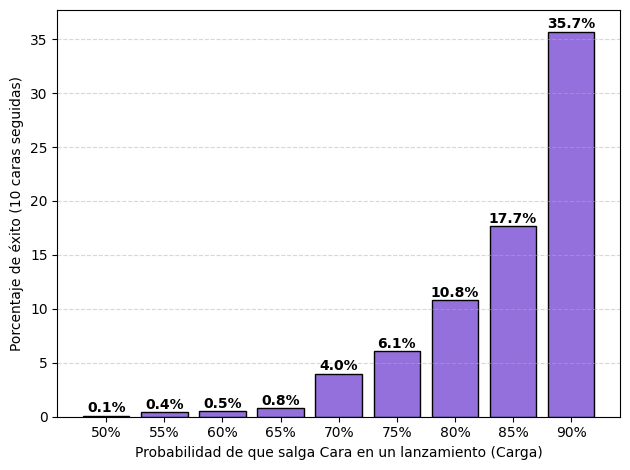

In [ ]:
# Configuración de la simulación
REPETICIONES_PER_PASO = 1000
LANZAMIENTOS = 10

# Definimos las probabilidades de 50% a 80%, de 5 en 5
probabilidades_cara = [p / 100 for p in range(50, 91, 5)]

# Diccionario para almacenar el porcentaje de éxito de cada probabilidad
porcentajes_exito = []

print("Iniciando simulación...")
print("-" * 60)

for p in probabilidades_cara:
    exitos_10_caras = 0

    for _ in range(REPETICIONES_PER_PASO):
        # Cada lanzamiento individual se define según la probabilidad 'p'
        lanzamientos = [1 if random.random() < p else 0 for _ in range(LANZAMIENTOS)]

        # Si la suma es 10, significa que todos los lanzamientos fueron 1 (Cara)
        if sum(lanzamientos) == 10:
            exitos_10_caras += 1

    # Calculamos el porcentaje de veces que se logró el objetivo
    porcentaje = (exitos_10_caras / REPETICIONES_PER_PASO) * 100
    porcentajes_exito.append(porcentaje)

    print(f"Moneda con {p*100:.0f}% de probabilidad de Cara -> Logró 10 caras: {exitos_10_caras} veces ({porcentaje:.1f}%)")

# --- Creación del Barplot ---

# Convertimos las probabilidades a strings para usarlas como etiquetas en el eje X
etiquetas_x = [f"{int(p*100)}%" for p in probabilidades_cara]

plt.bar(etiquetas_x, porcentajes_exito, color='mediumpurple', edgecolor='black')

plt.xlabel('Probabilidad de que salga Cara en un lanzamiento (Carga)')
plt.ylabel('Porcentaje de éxito (10 caras seguidas)')
#plt.title('¿Cómo afecta la carga de la moneda a la racha de 10 caras?')

# Añadir los valores exactos encima de cada barra
for i, v in enumerate(porcentajes_exito):
    plt.text(i, v + 0.3, f"{v:.1f}%", ha='center', fontweight='bold')

# Ajustes visuales
plt.ylim(0, max(porcentajes_exito) + 2)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()

# Guardar el gráfico resultante
plt.savefig('c1_simulacion_moneda_cargada.png')
print("-" * 60)